# 06 K近邻法 K-Nearest Neighbors(KNN)

## 1. 算法介绍



K近邻法可以用于**分类**和**回归**。

KNN 的核心思想是：一个新样本属于哪一类，可以参考它周围距离最近的 K 个样本。

假设有一个待预测样本 $x$：

1. 计算 $x$ 与训练集中所有样本之间的距离。
2. 按照距离从小到大排序。
3. 选择距离最近的 K 个样本。
4. 统计这 K 个样本分别属于哪些类别。
5. 哪个类别出现次数最多，就把 $x$ 分到哪个类别。

KNN 不仅能做分类，也可以做回归。如果是回归问题，找到最近的 K 个样本后，不再进行“投票”，而是计算这 K 个样本目标值的平均值。

K 是 KNN 中非常重要的参数。如果 K 太小，例如：K=1 模型容易受到噪声影响，可能出现**过拟合**。

如果 K 太大，则会考虑过多距离较远的样本，可能导致不同类别之间的差异被弱化，出现**欠拟合**。

## 2. 数学原理



假设训练数据集为：

$$
T=\{(x_1,y_1),(x_2,y_2),\dots,(x_n,y_n)\}
$$

其中：

$$
x_i\in R^m
$$

表示一个具有 $m$ 个特征的样本。

$y_i$ 表示对应的类别标签或数值。

现在有一个新的样本：x，需要预测它对应的类别或数值。

KNN 首先需要计算新样本 $x$ 与训练样本 $x_i$ 之间的距离。

最常用的是**欧氏距离**：

$$
d(x,x_i)
=
\sqrt{
\sum_{j=1}^{m}
(x_j-x_{ij})^2
}
$$

计算完新样本与所有训练样本之间的距离之后，将距离按照从小到大排序。

选出距离最小的 K 个样本，组成新样本的邻域：

$$
N_K(x)
$$

其中，$N_K(x)$ 表示样本 $x$ 的 K 个最近邻。

对于分类问题，KNN 使用**多数投票法**。

假设共有以下几个类别：

$$
c_1,c_2,\dots,c_M
$$

KNN 的分类结果可以表示为：

$$
\hat{y}
=
\arg\max_{c_j}
\sum_{x_i\in N_K(x)}
I(y_i=c_j)
$$

其中：

$$
I(y_i=c_j)
$$

是指示函数。

如果：

$$
y_i=c_j
$$

那么：

$$
I(y_i=c_j)=1
$$

否则：

$$
I(y_i=c_j)=0
$$

简单来说，就是统计 K 个最近邻中每个类别出现的次数。

对于回归问题，一般使用 K 个最近邻目标值的平均值作为预测结果：

$$
\hat{y}
=
\frac{1}{K}
\sum_{x_i\in N_K(x)}y_i
$$

例如：

$$
K=4
$$

最近 4 个样本的目标值分别为：

$$
8,\quad 10,\quad 11,\quad 15
$$

那么：

$$
\hat{y}
=
\frac{8+10+11+15}{4}
=11
$$

KNN 可以简单总结为：

$$
\text{计算距离}
\rightarrow
\text{寻找最近邻}
\rightarrow
\text{投票或求平均}
$$

对于分类问题：

$$
\text{距离}
\rightarrow
K\text{个最近邻}
\rightarrow
\text{多数投票}
$$

对于回归问题：

$$
\text{距离}
\rightarrow
K\text{个最近邻}
\rightarrow
\text{求平均值}
$$

## 3. 导入相关库

In [20]:
import numpy as np
import matplotlib.pyplot as plt

## 4. 构造数据

In [21]:
n = 1000
np.random.seed(42)
x1 = np.random.normal(
    loc = [3, 7],
    scale = 0.9,
    size = (n, 2)
)

x2 = np.random.normal(
    loc = [5, 2],
    scale = 0.6,
    size = (n, 2)
)

x3 = np.random.normal(
    loc = [1, 0],
    scale = 0.8,
    size = (n, 2)
)

x4 = np.random.normal(
    loc = [-1, 7],
    scale = 0.5,
    size = (n, 2)
)

X = np.vstack((x1, x2, x3, x4))

y1 = np.ones(n, dtype=int)
y2 = 2 * np.ones(n, dtype=int)
y3 = 3 * np.ones(n, dtype=int)
y4 = 4 * np.ones(n, dtype=int)
Y = np.concatenate((y1, y2, y3, y4))

## 5. 手动实现

In [22]:
def KNN(X, Y, X_test, k):
    y_pred = []
    for x in X_test:
        L = np.sqrt(np.sum((X-x)**2, axis = 1))
        k_index = np.argsort(L)[:k]
        k_labels = Y[k_index]
        
        labels, counts = np.unique(k_labels, return_counts=True)
        pred = labels[np.argmax(counts)]
        y_pred.append(pred)
        
    return np.array(y_pred)


## 6. 使用 scikit-learn 库实现

In [23]:
from sklearn.neighbors import KNeighborsClassifier

model = KNeighborsClassifier(n_neighbors=3)

# 训练模型
model.fit(X, Y)

# 预测
y_pred = model.predict([X_test])

print(y_pred)

[3]


## 7. 可视化

<function matplotlib.pyplot.show(close=None, block=None)>

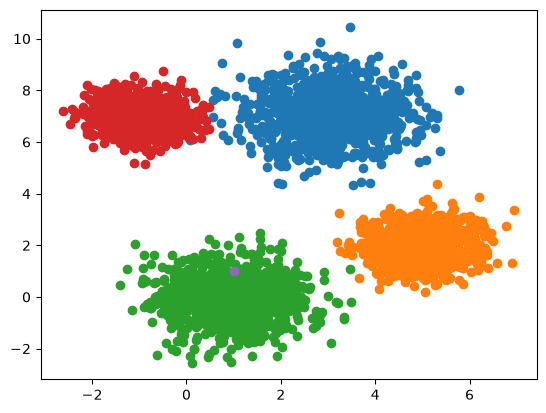

In [24]:
plt.scatter(x1[:,0], x1[:,1])
plt.scatter(x2[:,0], x2[:,1])
plt.scatter(x3[:,0], x3[:,1])
plt.scatter(x4[:,0], x4[:,1])

X_test=np.array([1,1])
plt.scatter(X_test[0], X_test[1])

plt.show

## 8.python新知识

1.3 * np.ones(n):生成全为3向量

2.X_train, y_train, X_test, k=3。给变量命名要直观一点

3.不仅可以for i 遍历，还可以对于x for x in X_test:遍历

4.axis=0(按列),axis=1(按行)

5.二维矩阵 (n, m) 减一个长度为 m 的向量时，通常就是每一行都减这个向量。np.sum((X_train-x)**2, axis = 1)必须要写axis = 1，否则会全部加和成一个数。

6.np.sort()：返回排序后的值。np.argsort()：返回排序后的下标

7.[:k] 是 Python 的切片，意思是：从开头取到第 k 个元素之前。可以直接跟在支持切片的对象后面。[:,0]表示所有行

8.np.unique(数组, return_counts=True)：返回“不重复的值”和“每个值出现的次数”。

9.汇总生成值：先生成空列表，再.append()

10.np.argmax(数组)：返回数组中最大值所在的下标。

11.np.array(y_pred)：列表转换为数组，计算更方便

12.model.fit(X_train, y_train)训练模型

13.二维数组需要在一维数组外面再加一个[]

14.plt.scatter(x, y)需要两个参数